# Results: Problem 1

Test-set results from `src/problem1/main.py`. Set `SPLIT` below to `"holdout"` (one split), `"kfold"` (mean ± std over the folds) or `"holdout_cv"` (train/test split, CV inside the training set). *default* = the classifier's own rule, *tuned* = threshold chosen on the validation set.

In [21]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Plot style: validated categorical palette, recessive grid and axes.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
TEXT, TEXT_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.edgecolor": TEXT_2, "axes.labelcolor": TEXT,
    "xtick.color": TEXT_2, "ytick.color": TEXT_2, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "legend.frameon": False, "axes.titlelocation": "left",
})
YELLOW = "#eda100"
METRICS = ["precision", "recall", "f1", "accuracy"]
METRIC_LABELS = {"precision": "Precision", "recall": "Recall", "f1": "F1", "accuracy": "Accuracy"}
METRIC_COLORS = [BLUE, ORANGE, AQUA, YELLOW]

# Which results to show: "holdout" (one 70/15/15 split), "kfold" (group k-fold)
# or "holdout_cv" (train/test split, cross-validation inside the training set).
SPLIT = "holdout"
SUFFIX = {"holdout": "", "kfold": "_kfold", "holdout_cv": "_cv"}[SPLIT]
YLABEL = "Test score (mean ± std over folds)" if SPLIT == "kfold" else "Score on test set"

RESULTS = "../results/problem1/"
results = {
    "1e": pd.read_csv(RESULTS + f"registry_results{SUFFIX}.csv"),
    "1f": pd.read_csv(RESULTS + f"full_results{SUFFIX}.csv"),
    "1h": pd.read_csv(RESULTS + f"bagging_results{SUFFIX}.csv"),
}
TITLES = {"1e": "(1e) Registry features", "1f": "(1f) Full features",
          "1h": "(1h) Bagging comparison"}
with open(RESULTS + f"run_config{SUFFIX}.json") as f:
    config = json.load(f)


def err(df, metric):
    """Standard deviations for error bars (0 where none is available)."""
    return df[metric + "_std"].fillna(0).values

## 1. Data split

Split by site: 70% / 15% / 15% (holdout), one row per fold (kfold), or 85% / 15% train / test (holdout_cv).

In [22]:
print("seed:", config["seed"], "| split:", config.get("split_method", "holdout"))
if SPLIT != "kfold":
    split = pd.DataFrame(config["split"]).T
else:
    split = pd.concat({f"fold {i + 1}": pd.DataFrame(s).T for i, s in enumerate(config["split"])})
split["positive_rate"] = split["positive_rate"].astype(float).round(3)
split

seed: 2026 | split: holdout


,sites,rows,positive_rate
train,347.0,2171.0,0.184
validation,74.0,462.0,0.193
test,75.0,483.0,0.207


## 2. Result tables

In [23]:
for key, df in results.items():
    print(TITLES[key])
    cols = ["model", "rule", "precision", "recall", "f1", "accuracy"]
    if SPLIT == "kfold":
        cols += ["precision_std", "recall_std", "f1_std", "accuracy_std"]
    display(df[cols + ["hyperparameters", "threshold"]].round(3))

(1e) Registry features


,model,rule,precision,recall,f1,accuracy,hyperparameters,threshold
0,Dummy (stratified),mean of 100 runs,0.208,0.185,0.196,0.685,"{""random_state"": ""2026-2125""}",NaN
1,Naive Bayes (Parzen),default,0.292,0.140,0.189,0.752,"{""bandwidth"": 0.1}",default
2,Naive Bayes (Parzen),tuned,0.285,0.450,0.349,0.652,"{""bandwidth"": 0.1}",0.1929
3,Least Squares,default,0.000,0.000,0.000,0.793,"{""reg_lambda"": 100000.0}",default
4,Least Squares,tuned,0.267,0.580,0.366,0.584,"{""reg_lambda"": 100000.0}",0.1847
5,MLP,default,0.000,0.000,0.000,0.793,"{""hidden_sizes"": [16], ""learning_rate"": 0.001,...",default
6,MLP,tuned,0.225,0.380,0.282,0.600,"{""hidden_sizes"": [16], ""learning_rate"": 0.001,...",0.2434


(1f) Full features


,model,rule,precision,recall,f1,accuracy,hyperparameters,threshold
0,Dummy (stratified),mean of 100 runs,0.208,0.185,0.196,0.685,"{""random_state"": ""2026-2125""}",NaN
1,Naive Bayes (Parzen),default,0.318,0.140,0.194,0.760,"{""bandwidth"": 0.25}",default
2,Naive Bayes (Parzen),tuned,0.302,0.670,0.416,0.611,"{""bandwidth"": 0.25}",0.1510
3,Least Squares,default,0.000,0.000,0.000,0.783,"{""reg_lambda"": 10.0}",default
4,Least Squares,tuned,0.294,0.580,0.391,0.625,"{""reg_lambda"": 10.0}",0.1925
5,MLP,default,0.290,0.220,0.250,0.727,"{""hidden_sizes"": [32, 16], ""learning_rate"": 0....",default
6,MLP,tuned,0.256,0.420,0.318,0.627,"{""hidden_sizes"": [32, 16], ""learning_rate"": 0....",0.0571


(1h) Bagging comparison


,model,rule,precision,recall,f1,accuracy,hyperparameters,threshold
0,Dummy (stratified),mean of 100 runs,0.208,0.185,0.196,0.685,"{""random_state"": ""2026-2125""}",NaN
1,Naive Bayes (Parzen),default,0.318,0.140,0.194,0.760,"{""bandwidth"": 0.25}",default
2,Naive Bayes (Parzen),tuned,0.302,0.670,0.416,0.611,"{""bandwidth"": 0.25}",0.1510
3,Least Squares,default,0.000,0.000,0.000,0.783,"{""reg_lambda"": 10.0}",default
4,Least Squares,tuned,0.294,0.580,0.391,0.625,"{""reg_lambda"": 10.0}",0.1925
5,MLP,default,0.290,0.220,0.250,0.727,"{""hidden_sizes"": [32, 16], ""learning_rate"": 0....",default
6,MLP,tuned,0.256,0.420,0.318,0.627,"{""hidden_sizes"": [32, 16], ""learning_rate"": 0....",0.0571
7,Bagged NB (Parzen),default,0.000,0.000,0.000,0.793,"{""bandwidth"": 4.0}",default
8,Bagged NB (Parzen),tuned,0.332,0.660,0.442,0.654,"{""bandwidth"": 4.0}",0.1827


## 3. Precision, recall, F1 and accuracy

Tuned threshold, with the dummy baseline.

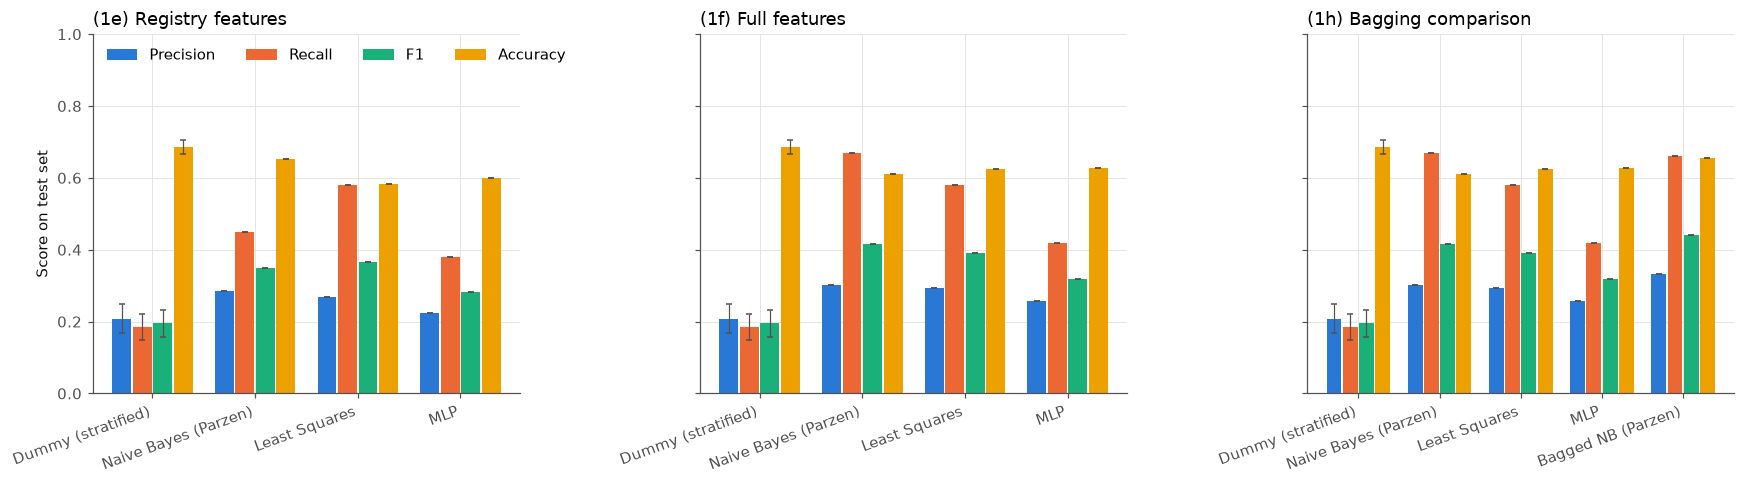

In [24]:
def table_for(df, rule):
    """Rows of the learned classifiers with `rule`, plus the dummy row."""
    keep = (df["rule"] == rule) | df["model"].str.startswith("Dummy")
    return df[keep].reset_index(drop=True)


def metric_bars(ax, df, title):
    x = np.arange(len(df))
    width = 0.2
    for j, (metric, color) in enumerate(zip(METRICS, METRIC_COLORS)):
        ax.bar(x + (j - 1.5) * width, df[metric], width * 0.92, color=color,
               yerr=err(df, metric), capsize=2, error_kw={"elinewidth": 0.8, "ecolor": TEXT_2},
               label=METRIC_LABELS[metric])
    for i, row in df.iterrows():          # bars of height 0 are invisible -> label them
        if row[METRICS].max() == 0:
            ax.text(x[i], 0.02, "all 0", ha="center", va="bottom", color=TEXT_2, fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels(df["model"], rotation=20, ha="right")
    ax.set_ylim(0, 1)
    ax.set_title(title)


fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, key in zip(axes, results):
    metric_bars(ax, table_for(results[key], "tuned"), TITLES[key])
axes[0].set_ylabel(YLABEL)
axes[0].legend(ncol=4, loc="upper left")
fig.tight_layout()

## 4. Default vs tuned threshold

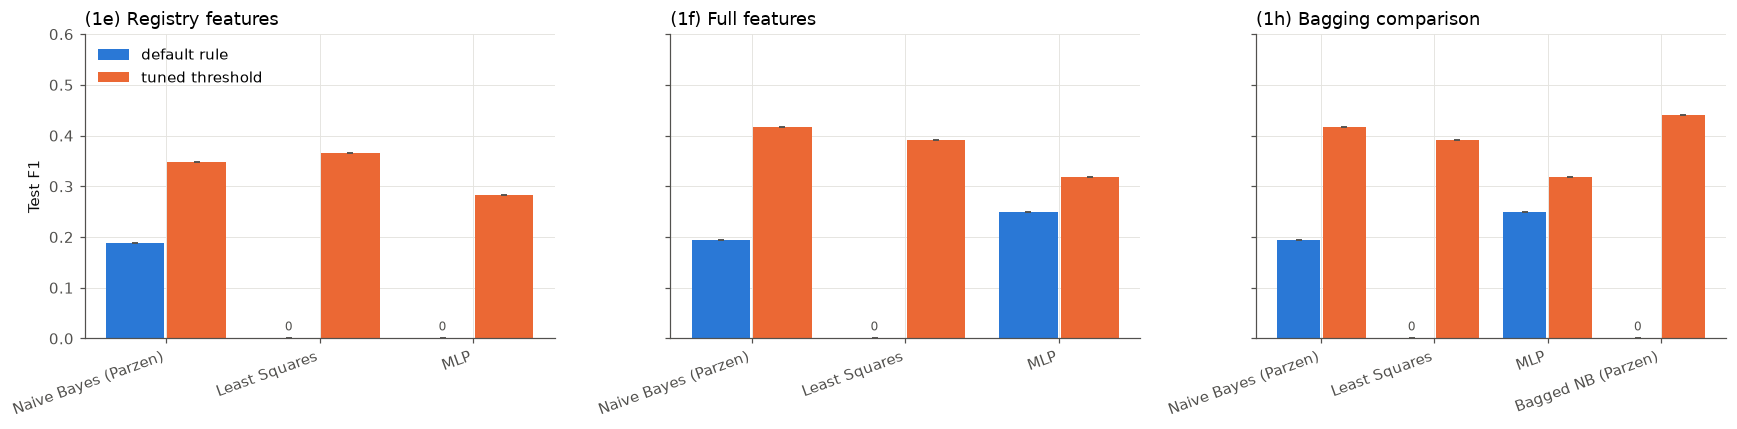

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, key in zip(axes, results):
    df = results[key]
    learned = df[~df["model"].str.startswith("Dummy")]
    models = learned["model"].unique()
    f1 = learned.pivot(index="model", columns="rule", values="f1").loc[models]
    f1_std = learned.pivot(index="model", columns="rule", values="f1_std").loc[models].fillna(0)
    x = np.arange(len(models))
    kw = {"capsize": 2, "error_kw": {"elinewidth": 0.8, "ecolor": TEXT_2}}
    ax.bar(x - 0.2, f1["default"], 0.38, color=BLUE, yerr=f1_std["default"], label="default rule", **kw)
    ax.bar(x + 0.2, f1["tuned"], 0.38, color=ORANGE, yerr=f1_std["tuned"], label="tuned threshold", **kw)
    for i, v in enumerate(f1["default"]):
        if v == 0:
            ax.text(x[i] - 0.2, 0.01, "0", ha="center", va="bottom", color=TEXT_2, fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(models, rotation=20, ha="right")
    ax.set_ylim(0, 0.6); ax.set_title(TITLES[key])
axes[0].set_ylabel("Test F1 (mean ± std over folds)" if SPLIT == "kfold" else "Test F1")
axes[0].legend(loc="upper left")
fig.tight_layout()

## 5. Registry vs full features (1e vs 1f)

,Δ precision,Δ recall,Δ f1,Δ accuracy
model,,,,
Naive Bayes (Parzen),0.017,0.22,0.067,-0.041
Least Squares,0.027,0.00,0.025,0.041
MLP,0.031,0.04,0.036,0.027


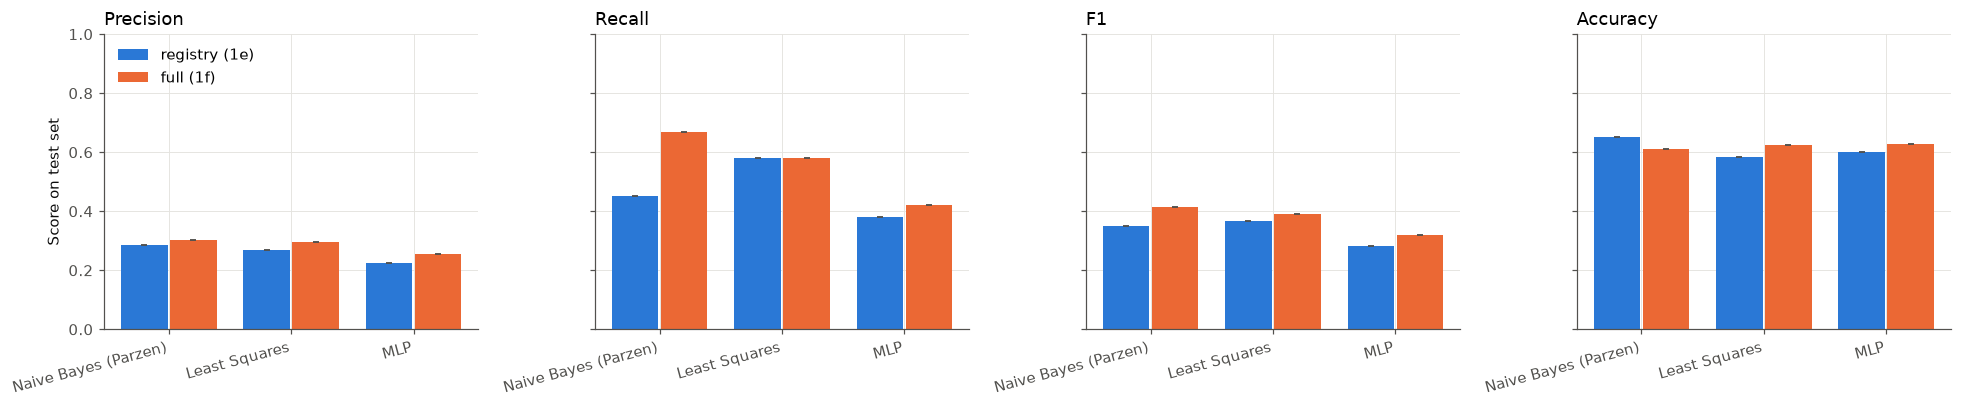

In [26]:
reg = table_for(results["1e"], "tuned").set_index("model")
full = table_for(results["1f"], "tuned").set_index("model")
models = [m for m in reg.index if not m.startswith("Dummy")]

fig, axes = plt.subplots(1, 4, figsize=(18, 3.8), sharey=True)
x = np.arange(len(models))
for ax, metric in zip(axes, METRICS):
    kw = {"capsize": 2, "error_kw": {"elinewidth": 0.8, "ecolor": TEXT_2}}
    ax.bar(x - 0.2, reg.loc[models, metric], 0.38, color=BLUE,
           yerr=reg.loc[models, metric + "_std"].fillna(0), label="registry (1e)", **kw)
    ax.bar(x + 0.2, full.loc[models, metric], 0.38, color=ORANGE,
           yerr=full.loc[models, metric + "_std"].fillna(0), label="full (1f)", **kw)
    ax.set_xticks(x); ax.set_xticklabels(models, rotation=15, ha="right")
    ax.set_title(METRIC_LABELS[metric])
    ax.set_ylim(0, 1)
axes[0].set_ylabel(YLABEL)
axes[0].legend(loc="upper left")
fig.tight_layout()

change = (full.loc[models, METRICS] - reg.loc[models, METRICS]).round(3)
change.columns = [f"Δ {m}" for m in METRICS]
change

## 6. Bagged vs unbagged naive Bayes (1h)

,model,rule,precision,recall,f1,accuracy
1,Naive Bayes (Parzen),default,0.318,0.14,0.194,0.760
2,Naive Bayes (Parzen),tuned,0.302,0.67,0.416,0.611
7,Bagged NB (Parzen),default,0.000,0.00,0.000,0.793
8,Bagged NB (Parzen),tuned,0.332,0.66,0.442,0.654


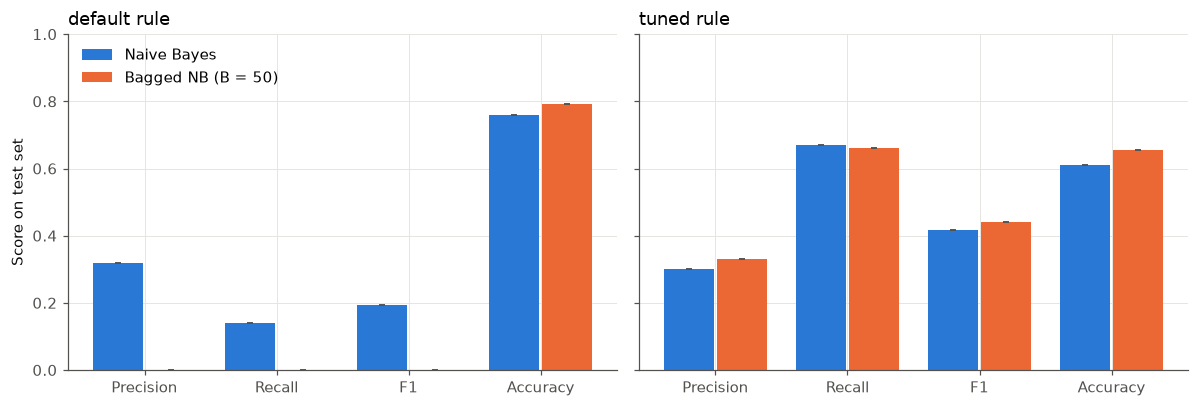

In [27]:
h = results["1h"]
nb_models = ["Naive Bayes (Parzen)", "Bagged NB (Parzen)"]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, rule in zip(axes, ["default", "tuned"]):
    sub = h[(h["rule"] == rule) & h["model"].isin(nb_models)].set_index("model").loc[nb_models]
    x = np.arange(len(METRICS))
    std = sub[[m + "_std" for m in METRICS]].fillna(0).values
    kw = {"capsize": 2, "error_kw": {"elinewidth": 0.8, "ecolor": TEXT_2}}
    ax.bar(x - 0.2, sub.loc[nb_models[0], METRICS], 0.38, color=BLUE, yerr=std[0],
           label="Naive Bayes", **kw)
    ax.bar(x + 0.2, sub.loc[nb_models[1], METRICS], 0.38, color=ORANGE, yerr=std[1],
           label="Bagged NB (B = 50)", **kw)
    ax.set_xticks(x); ax.set_xticklabels([METRIC_LABELS[m] for m in METRICS])
    ax.set_ylim(0, 1); ax.set_title(f"{rule} rule")
axes[0].set_ylabel(YLABEL)
axes[0].legend(loc="upper left")
fig.tight_layout()

h[h["model"].isin(nb_models)][["model", "rule", "precision", "recall", "f1", "accuracy"]].round(3)

## 7. Hyperparameter selection

Validation F1 of every hyperparameter setting (kfold: mean over the folds; holdout_cv: pooled inner-CV F1).

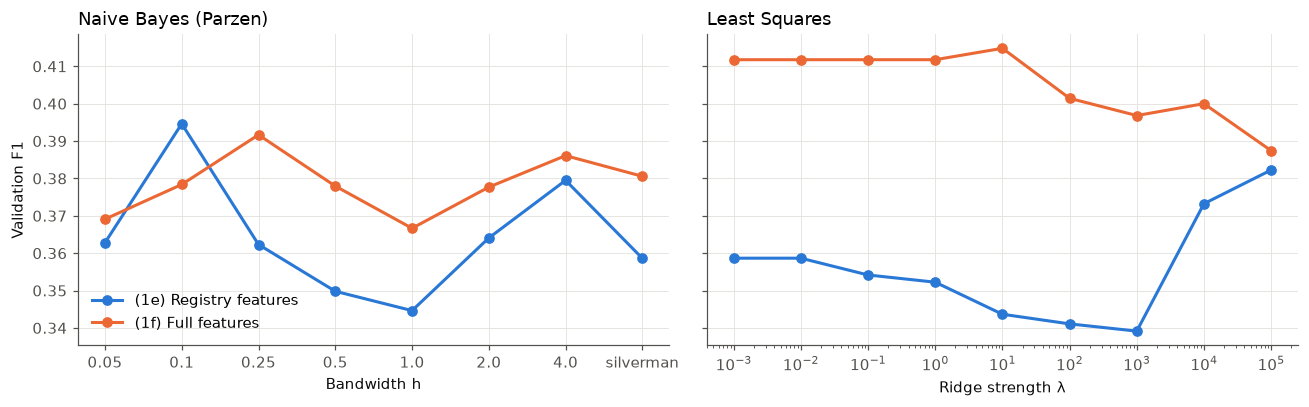

In [28]:
validation = config["validation"]
EXP_COLORS = {"(1e) Registry features": BLUE, "(1f) Full features": ORANGE}


def val_table(title, model):
    """Validation F1 per setting; for k-fold the mean over the folds."""
    entry = validation[title][model]
    folds = entry if SPLIT == "kfold" else [entry]          # list of folds, each a list of settings
    table = pd.DataFrame([{**r["params"]} for r in folds[0]])
    table["val_f1"] = np.mean([[r["val_f1_tuned"] for r in fold] for fold in folds], axis=0)
    return table


fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)

# Naive Bayes: bandwidth h (categorical axis, includes "silverman").
for title, color in EXP_COLORS.items():
    t = val_table(title, "Naive Bayes (Parzen)")
    axes[0].plot(t["bandwidth"].astype(str), t["val_f1"], color=color, lw=2,
                 marker="o", ms=6, label=title)
axes[0].set_xlabel("Bandwidth h"); axes[0].set_ylabel("Validation F1")
axes[0].set_title("Naive Bayes (Parzen)")
axes[0].legend(loc="lower left")

# Least squares: ridge strength λ (log axis).
for title, color in EXP_COLORS.items():
    t = val_table(title, "Least Squares")
    axes[1].plot(t["reg_lambda"], t["val_f1"], color=color, lw=2, marker="o", ms=6, label=title)
axes[1].set_xscale("log")
axes[1].set_xlabel("Ridge strength λ"); axes[1].set_title("Least Squares")
fig.tight_layout()

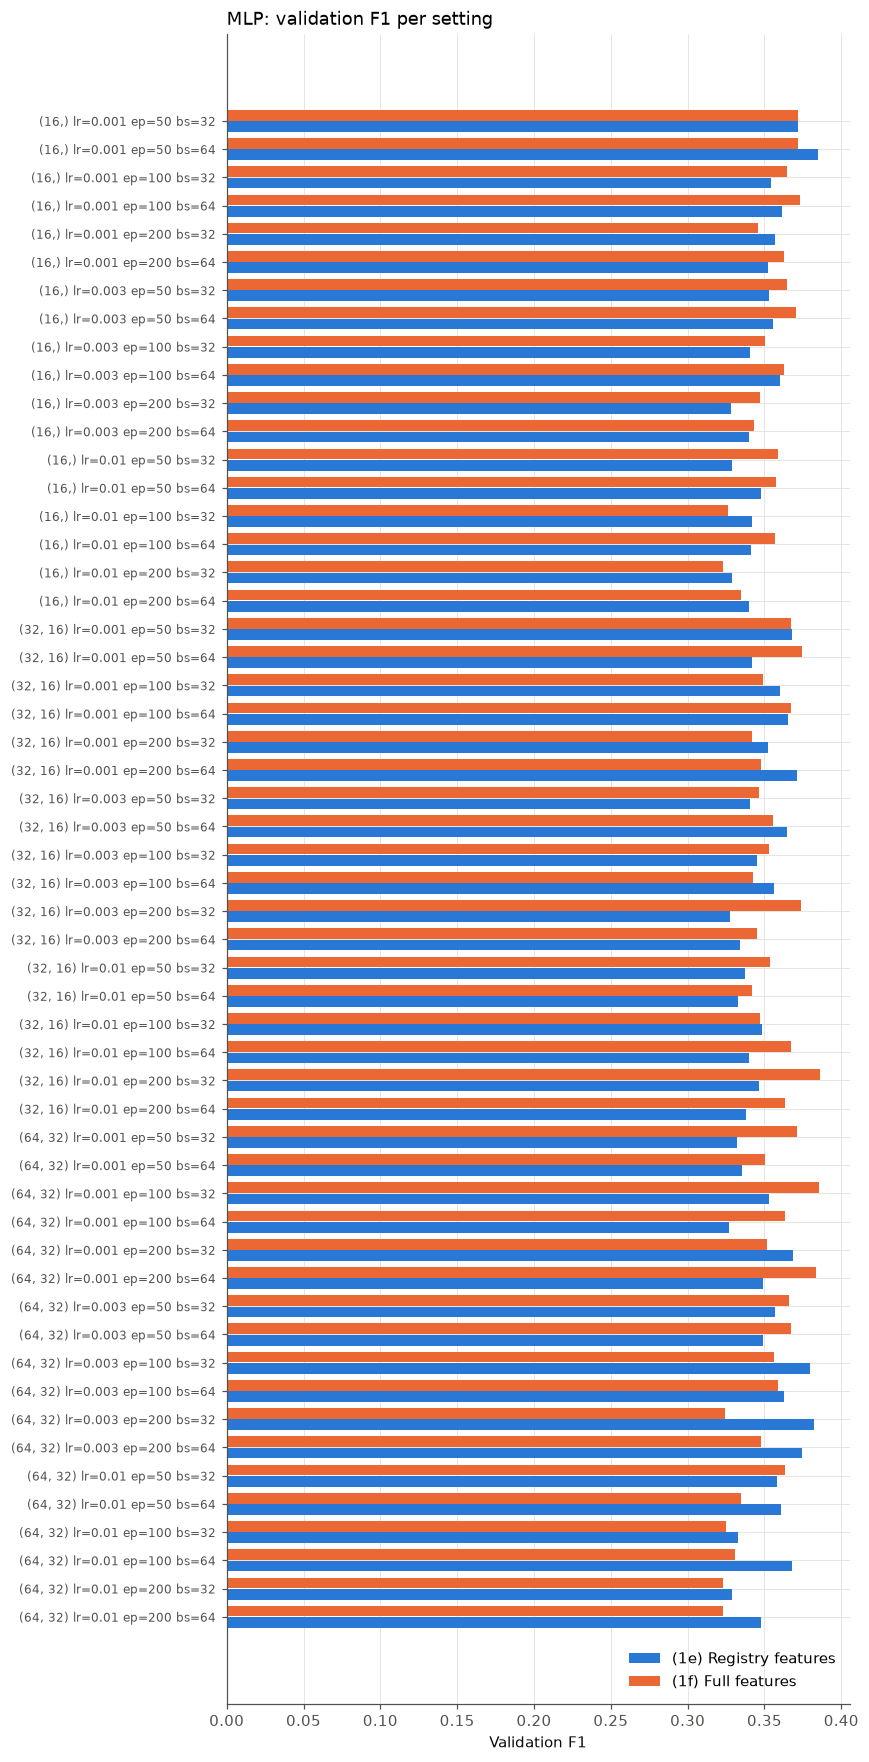

In [29]:
# MLP: one bar per setting and experiment.
t_e = val_table("(1e) Registry features", "MLP")
t_f = val_table("(1f) Full features", "MLP")
labels = [f"{tuple(r.hidden_sizes)} lr={r.learning_rate:g} ep={r.n_epochs} bs={r.batch_size}"
          for r in t_e.itertuples()]

fig, ax = plt.subplots(figsize=(8, 0.28 * len(labels) + 1))
yy = np.arange(len(labels))
ax.barh(yy + 0.2, t_e["val_f1"], 0.38, color=BLUE, label="(1e) Registry features")
ax.barh(yy - 0.2, t_f["val_f1"], 0.38, color=ORANGE, label="(1f) Full features")
ax.set_yticks(yy); ax.set_yticklabels(labels, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("Validation F1"); ax.set_title("MLP: validation F1 per setting")
ax.legend(loc="lower right")
fig.tight_layout()

In [30]:
# Selected hyperparameters and thresholds per experiment and classifier.
selected = []
for key, df in results.items():
    for r in df[df["rule"] == "tuned"].itertuples():
        selected.append({"experiment": key, "model": r.model,
                         "hyperparameters": r.hyperparameters, "threshold": r.threshold})
pd.DataFrame(selected)

,experiment,model,hyperparameters,threshold
0,1e,Naive Bayes (Parzen),"{""bandwidth"": 0.1}",0.1929
1,1e,Least Squares,"{""reg_lambda"": 100000.0}",0.1847
2,1e,MLP,"{""hidden_sizes"": [16], ""learning_rate"": 0.001,...",0.2434
3,1f,Naive Bayes (Parzen),"{""bandwidth"": 0.25}",0.1510
4,1f,Least Squares,"{""reg_lambda"": 10.0}",0.1925
5,1f,MLP,"{""hidden_sizes"": [32, 16], ""learning_rate"": 0....",0.0571
6,1h,Naive Bayes (Parzen),"{""bandwidth"": 0.25}",0.1510
7,1h,Least Squares,"{""reg_lambda"": 10.0}",0.1925
8,1h,MLP,"{""hidden_sizes"": [32, 16], ""learning_rate"": 0....",0.0571
9,1h,Bagged NB (Parzen),"{""bandwidth"": 4.0}",0.1827


### 7.1 Validation metrics of every setting

Precision, recall, F1 and accuracy on the validation data for every hyperparameter setting (kfold: mean over the folds); `selected` marks the chosen setting.

In [31]:
FILES = {"1e": "registry", "1f": "full", "1h": "bagging"}
VAL_COLS = [f"val_{m}_{rule}" for rule in ("default", "tuned") for m in METRICS]

for key, name in FILES.items():
    val = pd.read_csv(RESULTS + f"{name}_validation{SUFFIX}.csv")
    if SPLIT == "kfold":
        # Mean over the folds; `selected` = number of folds that chose the setting.
        val = (val.groupby(["model", "hyperparameters"], sort=False)
                  .agg({**{c: "mean" for c in VAL_COLS}, "selected": "sum"}).reset_index())
    val = val.sort_values(["model", "val_f1_tuned"], ascending=[True, False], kind="stable")
    print(TITLES[key])
    display(val[["model", "hyperparameters", "selected"] + VAL_COLS].round(3)
            .style.apply(lambda r: ["font-weight: bold" if r["selected"] else ""] * len(r), axis=1)
            .format(precision=3).hide(axis="index"))

(1e) Registry features


model,hyperparameters,selected,val_precision_default,val_recall_default,val_f1_default,val_accuracy_default,val_precision_tuned,val_recall_tuned,val_f1_tuned,val_accuracy_tuned
Least Squares,"{""reg_lambda"": 100000.0}",1,0.000,0.000,0.000,0.807,0.274,0.629,0.382,0.608
Least Squares,"{""reg_lambda"": 10000.0}",0,0.000,0.000,0.000,0.807,0.272,0.596,0.373,0.615
Least Squares,"{""reg_lambda"": 0.001}",0,0.143,0.022,0.039,0.786,0.246,0.663,0.359,0.543
Least Squares,"{""reg_lambda"": 0.01}",0,0.143,0.022,0.039,0.786,0.246,0.663,0.359,0.543
Least Squares,"{""reg_lambda"": 0.1}",0,0.143,0.022,0.039,0.786,0.230,0.764,0.354,0.463
Least Squares,"{""reg_lambda"": 1.0}",0,0.143,0.022,0.039,0.786,0.240,0.663,0.352,0.530
Least Squares,"{""reg_lambda"": 10.0}",0,0.000,0.000,0.000,0.807,0.229,0.685,0.344,0.496
Least Squares,"{""reg_lambda"": 100.0}",0,0.000,0.000,0.000,0.807,0.222,0.742,0.341,0.448
Least Squares,"{""reg_lambda"": 1000.0}",0,0.000,0.000,0.000,0.807,0.218,0.764,0.339,0.426
MLP,"{""hidden_sizes"": [16], ""learning_rate"": 0.001, ""n_epochs"": 50, ""batch_size"": 64}",1,0.571,0.045,0.083,0.810,0.331,0.461,0.385,0.716


(1f) Full features


model,hyperparameters,selected,val_precision_default,val_recall_default,val_f1_default,val_accuracy_default,val_precision_tuned,val_recall_tuned,val_f1_tuned,val_accuracy_tuned
Least Squares,"{""reg_lambda"": 10.0}",1,0.650,0.146,0.238,0.820,0.309,0.629,0.415,0.658
Least Squares,"{""reg_lambda"": 0.001}",0,0.469,0.168,0.248,0.803,0.329,0.551,0.412,0.697
Least Squares,"{""reg_lambda"": 0.01}",0,0.469,0.168,0.248,0.803,0.329,0.551,0.412,0.697
Least Squares,"{""reg_lambda"": 0.1}",0,0.469,0.168,0.248,0.803,0.329,0.551,0.412,0.697
Least Squares,"{""reg_lambda"": 1.0}",0,0.467,0.157,0.235,0.803,0.329,0.551,0.412,0.697
Least Squares,"{""reg_lambda"": 100.0}",0,0.667,0.135,0.224,0.820,0.295,0.629,0.401,0.638
Least Squares,"{""reg_lambda"": 10000.0}",0,0.000,0.000,0.000,0.807,0.347,0.472,0.400,0.727
Least Squares,"{""reg_lambda"": 1000.0}",0,0.714,0.056,0.104,0.814,0.307,0.562,0.397,0.671
Least Squares,"{""reg_lambda"": 100000.0}",0,0.000,0.000,0.000,0.807,0.363,0.416,0.387,0.747
MLP,"{""hidden_sizes"": [32, 16], ""learning_rate"": 0.01, ""n_epochs"": 200, ""batch_size"": 32}",1,0.333,0.303,0.318,0.749,0.294,0.562,0.386,0.656


(1h) Bagging comparison


model,hyperparameters,selected,val_precision_default,val_recall_default,val_f1_default,val_accuracy_default,val_precision_tuned,val_recall_tuned,val_f1_tuned,val_accuracy_tuned
Bagged NB (Parzen),"{""bandwidth"": 4.0}",1,0.000,0.000,0.000,0.807,0.290,0.607,0.393,0.638
Bagged NB (Parzen),"{""bandwidth"": 0.25}",0,0.388,0.214,0.275,0.784,0.333,0.472,0.391,0.716
Bagged NB (Parzen),"{""bandwidth"": 2.0}",0,1.000,0.022,0.044,0.812,0.279,0.640,0.389,0.613
Bagged NB (Parzen),"{""bandwidth"": 0.5}",0,0.462,0.202,0.281,0.801,0.310,0.494,0.381,0.690
Bagged NB (Parzen),"{""bandwidth"": ""silverman""}",0,0.318,0.157,0.210,0.773,0.283,0.584,0.381,0.634
Bagged NB (Parzen),"{""bandwidth"": 0.1}",0,0.343,0.258,0.295,0.762,0.303,0.483,0.372,0.686
Bagged NB (Parzen),"{""bandwidth"": 1.0}",0,0.591,0.146,0.234,0.816,0.258,0.640,0.368,0.576
Bagged NB (Parzen),"{""bandwidth"": 0.05}",0,0.342,0.281,0.309,0.758,0.314,0.427,0.362,0.710
Least Squares,"{""reg_lambda"": 10.0}",1,0.650,0.146,0.238,0.820,0.309,0.629,0.415,0.658
Least Squares,"{""reg_lambda"": 0.001}",0,0.469,0.168,0.248,0.803,0.329,0.551,0.412,0.697
